<a href="https://colab.research.google.com/github/HITESH8842/dataviz-exercises-M-Hitesh/blob/main/Quiz%201/dataviz_quiz1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Data Visualization — Quiz (Lectures 1–7)

**Time:** 90 minutes
**Tools:** Plotly only (`plotly.express` first, then `update_traces` / `update_layout` / `update_xaxes` / `update_yaxes`)

**Your task:** answer each analytical question with **one polished, explanatory visualization**. For every question **you decide which chart type fits best** — and justify the choice in one or two sentences.

**Every figure must have:**
1. An **insight title** that states the finding, not just the variables
2. `template='plotly_white'` and a decluttered layout (no unnecessary gridlines, legends or axis titles)
3. A **CVD-safe palette** — no red/green; grey for context + one accent colour where it helps
4. Colour that **encodes meaning**, not decoration
5. Direct labels or annotations where they help the reader

**Chart types covered in the course** — choose from these:
line chart · sorted bar chart · stacked / 100% stacked bar chart · scatter plot · bubble chart · histogram · box plot · violin plot · choropleth map · treemap

> 💡 Each question has one chart type that fits it best, and the questions together cover most of the list above. If two of your answers use the same chart type, check the question again.


**Submit:** this notebook pushed to your personal repo as `quiz/dataviz_quiz.ipynb`

## The dataset — World Population 1970–2022

**Source:** [World Population Dataset](https://www.kaggle.com/datasets/iamsouravbanerjee/world-population-dataset) on Kaggle, compiled from Worldometer (UN World Population Prospects estimates). **234 rows × 16 columns — one row per country or territory, no missing values.**

| Column | Type | Description |
|---|---|---|
| `Country`, `Capital` | categorical | Country / territory and its capital |
| `Continent` | categorical | Africa, Asia, Europe, North America, Oceania, South America |
| `CCA3` | spatial | ISO-3 country code — use with `locationmode='ISO-3'` |
| `1970 Population` … `2022 Population` | temporal | Population in 1970, 1980, 1990, 2000, 2010, 2015, 2020, 2022 |
| `Area` | numerical | Land area in km² |
| `Density` | numerical | People per km² (2022) |
| `World share (%)` | numerical | Share of world population in 2022 |
| `Rank` | numerical | Rank by 2022 population |

**The next setup cell also gives you `df_long` — the same data in **tidy (long) format** with one row per country per year. Use `df` for one-year questions and `df_long` for questions about change over time**

**Setup (Google Colab):** run the install cell below once, then click **Runtime → Restart session**, then **Runtime → Run all**. This lets the charts be saved as images so they show on GitHub.

In [1]:
# Run once, then Runtime → Restart session
!pip install -q plotly==5.24.1 kaleido==0.2.1

In [5]:
import pandas as pd
import plotly.express as px
import numpy as np
import plotly.io as pio

# Show charts as PNG images so they also display on GitHub
pio.renderers.default = 'png'
pio.renderers['png'].width = 1000

df = pd.read_csv('world_population.csv')

# Shorter column names
df = df.rename(columns={'Country/Territory': 'Country', 'Area (km²)': 'Area',
                        'Density (per km²)': 'Density', 'World Population Percentage': 'World share (%)'})

# Tidy (long) version: one row per country per year
year_cols = [c for c in df.columns if c.endswith('Population')]
df_long = df.melt(id_vars=['CCA3', 'Country', 'Continent'], value_vars=year_cols,
                  var_name='Year', value_name='Population')

df_long['Year'] = df_long['Year'].str[:4].astype(int)     # '2022 Population' → 2022

print(df.shape, df_long.shape)


(234, 16) (1872, 5)


---
## Q1 — Which continent is growing fastest?

How has the population of each continent **grown since 1970, relative to its 1970 size** — and which continent is growing fastest?


**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.*

I went with a line chart because this question is really about change over time, and lines make trends easy to follow. If I had plotted the raw population numbers, Asia would have dominated the chart just because it's so big, so I divided each continent by its own 1970 population. Now every line starts at 100, and you can compare how fast each continent grew compared to where it started.

Africa is the answer, so I made it the only orange line and left the rest grey. Instead of a legend I put the names at the end of the lines, with the growth factor next to them, so you don't have to look back and forth. The dotted line at 100 is there so you can see straight away that Europe has barely moved since 1970.

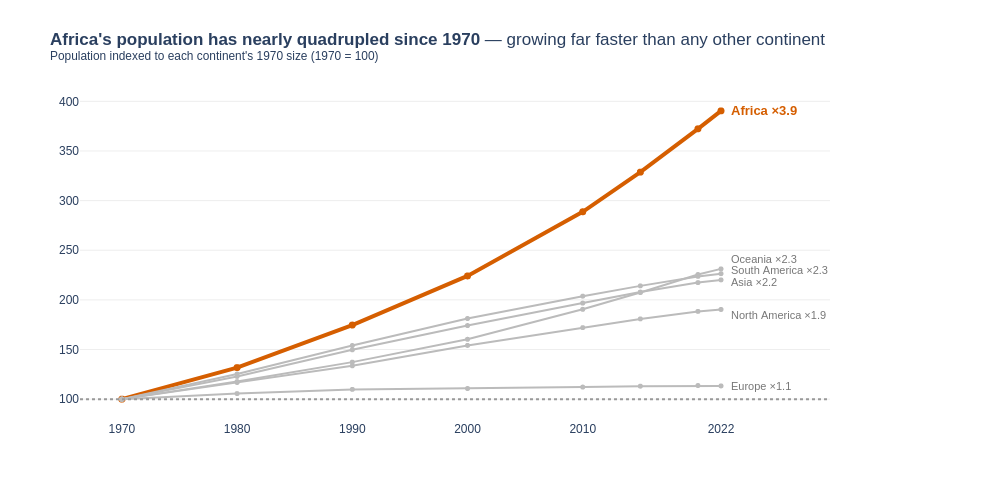

,1970 Population,2022 Population,Growth factor (×),Growth (%)
Continent,,,,
Africa,"365,444,348","1,426,730,932",3.90,290.4%
Oceania,"19,480,270","45,038,554",2.31,131.2%
South America,"192,947,156","436,816,608",2.26,126.4%
Asia,"2,144,906,290","4,721,383,274",2.20,120.1%
North America,"315,434,606","600,296,136",1.90,90.3%
Europe,"655,923,991","743,147,538",1.13,13.3%


In [6]:
# Q1 — Line chart: population growth indexed to 1970 = 100
ACCENT, GREY = '#D55E00', '#BBBBBB'

cont = df_long.groupby(['Continent', 'Year'], as_index=False)['Population'].sum()
base = cont[cont['Year'] == 1970].set_index('Continent')['Population']
cont['Index'] = cont['Population'] / cont['Continent'].map(base) * 100

colors = {c: (ACCENT if c == 'Africa' else GREY) for c in cont['Continent'].unique()}

fig = px.line(cont, x='Year', y='Index', color='Continent',
              color_discrete_map=colors, markers=True,
              template='plotly_white',
              title="<b>Africa's population has nearly quadrupled since 1970</b> — "
                    "growing far faster than any other continent"
                    "<br><sup>Population indexed to each continent's 1970 size (1970 = 100)</sup>")

fig.update_traces(line=dict(width=2), marker=dict(size=5))
fig.update_traces(selector=dict(name='Africa'), line=dict(width=4), marker=dict(size=7))

# Direct labels at the end of each line instead of a legend
last = cont[cont['Year'] == 2022].sort_values('Index')
# nudge the bunched grey labels so they don't overlap
offsets = {'Europe': 0, 'North America': -6, 'Asia': -2, 'South America': 4, 'Oceania': 10, 'Africa': 0}
for _, r in last.iterrows():
    is_af = r['Continent'] == 'Africa'
    fig.add_annotation(x=2022, y=r['Index'] + offsets.get(r['Continent'], 0),
                       text=f"<b>{r['Continent']} ×{r['Index']/100:.1f}</b>" if is_af
                            else f"{r['Continent']} ×{r['Index']/100:.1f}",
                       showarrow=False, xanchor='left', xshift=8,
                       font=dict(color=ACCENT if is_af else '#777777', size=13 if is_af else 11))

fig.add_hline(y=100, line_dash='dot', line_color='#999999')
fig.update_layout(showlegend=False, margin=dict(r=170, t=90), height=500)
fig.update_xaxes(title=None, showgrid=False, tickvals=[1970, 1980, 1990, 2000, 2010, 2022])
fig.update_yaxes(title=None, showgrid=True, gridcolor='#EEEEEE', ticksuffix='')
fig.show()

# Summary table — growth since 1970 by continent
q1_table = (cont.pivot(index='Continent', columns='Year', values='Population')[[1970, 2022]]
              .rename(columns={1970: '1970 Population', 2022: '2022 Population'}))
q1_table.columns.name = None
q1_table['Growth factor (×)'] = q1_table['2022 Population'] / q1_table['1970 Population']
q1_table['Growth (%)'] = (q1_table['Growth factor (×)'] - 1) * 100
q1_table = q1_table.sort_values('Growth factor (×)', ascending=False)
display(q1_table.style.format({'1970 Population': '{:,.0f}', '2022 Population': '{:,.0f}',
                               'Growth factor (×)': '{:.2f}', 'Growth (%)': '{:.1f}%'}))

---
## Q2 — Which countries added the most people?

Which **15 countries added the most people** between 1970 and 2022 — and how many of them are in **Africa**?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.*

This one is basically a ranking, so I used a sorted bar chart. Bars are the easiest thing to compare by length, and sorting them from biggest to smallest means you can read the ranking from top to bottom without thinking about it. I turned the bars sideways so the country names fit and stay readable.

The second part of the question asks how many of the 15 countries are in Africa, so I coloured the African countries orange and left everything else grey. You can count them in a second (there are 4). I wrote the numbers at the end of each bar, so I didn't need the x-axis or gridlines and removed them to keep it clean.

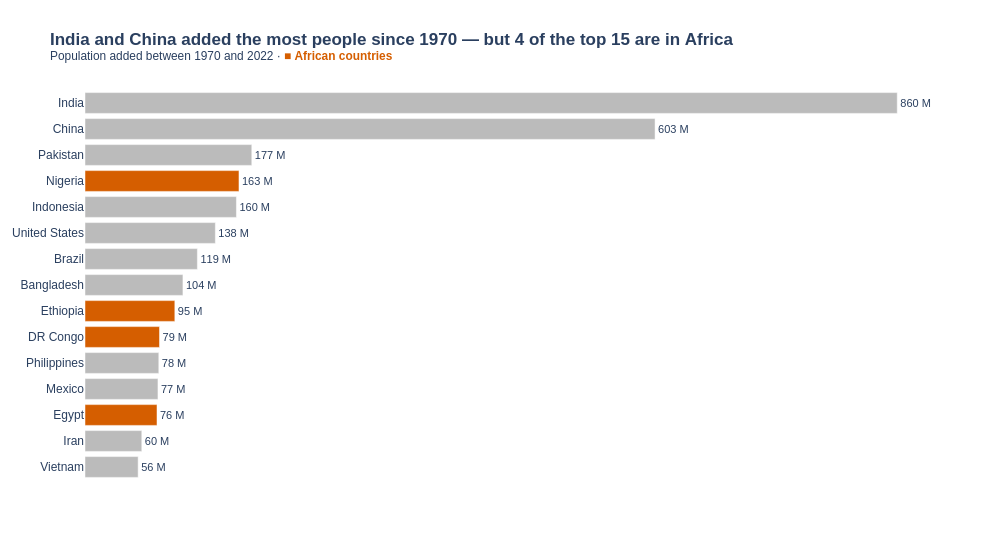

African countries in the top 15: 4


,Country,Continent,1970 Population,2022 Population,Added
1,India,Asia,"557,501,301","1,417,173,173","859,671,872"
2,China,Asia,"822,534,450","1,425,887,337","603,352,887"
3,Pakistan,Asia,"59,290,872","235,824,862","176,533,990"
4,Nigeria,Africa,"55,569,264","218,541,212","162,971,948"
5,Indonesia,Asia,"115,228,394","275,501,339","160,272,945"
6,United States,North America,"200,328,340","338,289,857","137,961,517"
7,Brazil,South America,"96,369,875","215,313,498","118,943,623"
8,Bangladesh,Asia,"67,541,860","171,186,372","103,644,512"
9,Ethiopia,Africa,"28,308,246","123,379,924","95,071,678"
10,DR Congo,Africa,"20,151,733","99,010,212","78,858,479"


In [7]:
# Q2 — Sorted bar chart: top 15 countries by people added 1970→2022
ACCENT, GREY = '#D55E00', '#BBBBBB'

top = df.assign(Added=df['2022 Population'] - df['1970 Population']) \
        .nlargest(15, 'Added').sort_values('Added')          # ascending → largest on top
top['Group'] = np.where(top['Continent'] == 'Africa', 'Africa', 'Other continents')
n_africa = (top['Continent'] == 'Africa').sum()

fig = px.bar(top, x='Added', y='Country', orientation='h', color='Group',
             color_discrete_map={'Africa': ACCENT, 'Other continents': GREY},
             text=(top['Added'] / 1e6).round(0).astype(int).astype(str) + ' M',
             template='plotly_white',
             title=f"<b>India and China added the most people since 1970 — "
                   f"but {n_africa} of the top 15 are in Africa</b>"
                   f"<br><sup>Population added between 1970 and 2022 · "
                   f"<span style='color:{ACCENT}'><b>■ African countries</b></span></sup>")

fig.update_traces(textposition='outside', cliponaxis=False, textfont_size=11)
fig.update_layout(showlegend=False, height=560, margin=dict(t=90, r=60),
                  yaxis=dict(categoryorder='array', categoryarray=top['Country']))
fig.update_xaxes(visible=False, showgrid=False)
fig.update_yaxes(title=None, showgrid=False)
fig.show()

# Summary table — top 15 countries by people added
q2_table = top.sort_values('Added', ascending=False)[['Country', 'Continent', '1970 Population', '2022 Population', 'Added']]
q2_table.index = range(1, len(q2_table) + 1)
print(f"African countries in the top 15: {n_africa}")
display(q2_table.style.format({'1970 Population': '{:,.0f}', '2022 Population': '{:,.0f}', 'Added': '{:,.0f}'}))

---
## Q3 — Do bigger countries have more people?

Is there a relationship between a country's **land area** and its **2022 population** — does it differ by **continent**, and which countries clearly break the pattern?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.*

Two numbers per country and the question "are they related?" is exactly what a scatter plot is for. The first time I plotted it, almost every country was squeezed into the bottom-left corner because a few countries are huge, so I switched both axes to a log scale. After that the pattern was easy to see: bigger countries do tend to have more people.

I added a dashed trend line so it's obvious which countries break the pattern, and I labelled the most extreme ones. Places like Macau, Singapore and Bangladesh sit way above the line, and Greenland, Mongolia and Australia sit way below it. I coloured the dots by continent using a colour-blind-friendly palette without red and green, because the question also asks whether the pattern differs between continents. You can see that a lot of the Asian countries sit above the line.

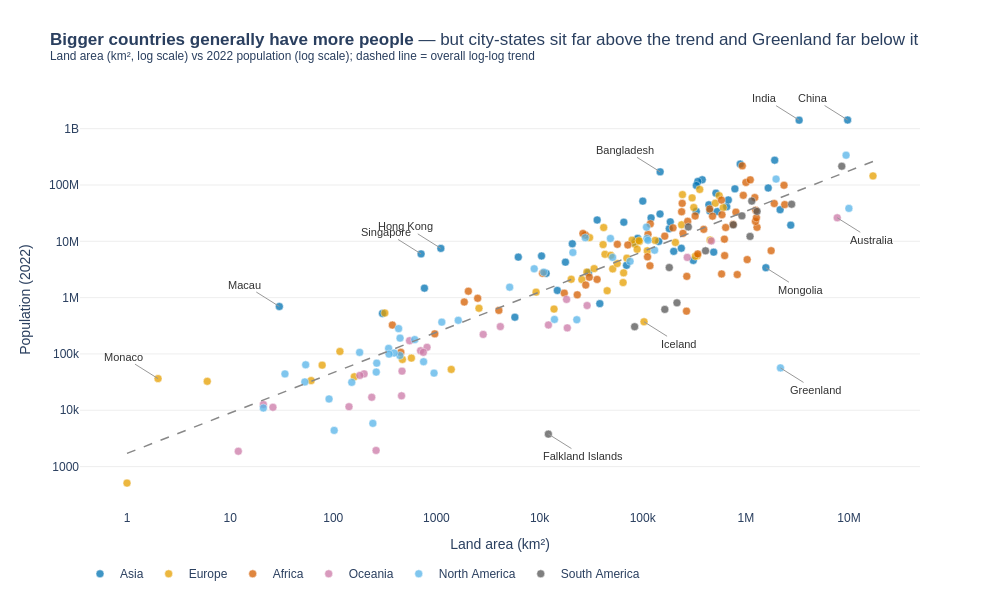

Correlation of log(area) and log(population): r = 0.87


,Position,Country,Continent,Area,2022 Population,Density
0,Far above trend (crowded),Macau,Asia,30,"695,168","23,172.3"
1,Far above trend (crowded),Singapore,Asia,710,"5,975,689","8,416.5"
2,Far above trend (crowded),Hong Kong,Asia,"1,104","7,488,865","6,783.4"
3,Far above trend (crowded),Bangladesh,Asia,"147,570","171,186,372","1,160.0"
4,Far above trend (crowded),India,Asia,"3,287,590","1,417,173,173",431.1
5,Far below trend (empty),Greenland,North America,"2,166,086","56,466",0.0
6,Far below trend (empty),Falkland Islands,South America,"12,173","3,780",0.3
7,Far below trend (empty),Niue,Oceania,260,"1,934",7.4
8,Far below trend (empty),Western Sahara,Africa,"266,000","575,986",2.2
9,Far below trend (empty),French Guiana,South America,"83,534","304,557",3.6


In [8]:
# Q3 — Scatter plot: land area vs 2022 population (log-log)
PALETTE = {'Africa': '#D55E00', 'Asia': '#0072B2', 'Europe': '#E69F00',
           'North America': '#56B4E9', 'Oceania': '#CC79A7', 'South America': '#555555'}

fig = px.scatter(df, x='Area', y='2022 Population', color='Continent',
                 color_discrete_map=PALETTE, hover_name='Country',
                 log_x=True, log_y=True, opacity=0.75,
                 template='plotly_white',
                 title="<b>Bigger countries generally have more people</b> — "
                       "but city-states sit far above the trend and Greenland far below it"
                       "<br><sup>Land area (km², log scale) vs 2022 population (log scale); "
                       "dashed line = overall log-log trend</sup>")

# Overall trend line fitted on log10 values
lx, ly = np.log10(df['Area']), np.log10(df['2022 Population'])
slope, intercept = np.polyfit(lx, ly, 1)
xs = np.logspace(lx.min(), lx.max(), 50)
fig.add_scatter(x=xs, y=10 ** (intercept + slope * np.log10(xs)), mode='lines',
                line=dict(color='#888888', dash='dash', width=1.5),
                showlegend=False, hoverinfo='skip')

# Label the countries that clearly break the pattern
outliers = ['Macau', 'Singapore', 'Hong Kong', 'Bangladesh', 'India', 'China',
            'Monaco', 'Greenland', 'Falkland Islands', 'Mongolia', 'Australia', 'Iceland']
for _, r in df[df['Country'].isin(outliers)].iterrows():
    above = (np.log10(r['2022 Population']) - (intercept + slope * np.log10(r['Area']))) > 0
    fig.add_annotation(x=np.log10(r['Area']), y=np.log10(r['2022 Population']),
                       text=r['Country'], showarrow=True, arrowhead=0, arrowwidth=1,
                       arrowcolor='#999999', ax=-35 if above else 35, ay=-22 if above else 22,
                       font=dict(size=11, color='#333333'))

fig.update_traces(marker=dict(size=8, line=dict(width=0.5, color='white')),
                  selector=dict(mode='markers'))
fig.update_layout(height=600, margin=dict(t=90),
                  legend=dict(title=None, orientation='h', y=-0.12, x=0))
fig.update_xaxes(title='Land area (km²)', showgrid=False)
fig.update_yaxes(title='Population (2022)', showgrid=True, gridcolor='#EEEEEE')
fig.show()

# Summary table — countries that break the pattern most (distance from the trend line)
q3 = df.assign(Residual=ly - (intercept + slope * lx))
q3_table = pd.concat([q3.nlargest(5, 'Residual').assign(Position='Far above trend (crowded)'),
                      q3.nsmallest(5, 'Residual').assign(Position='Far below trend (empty)')])
q3_table = q3_table[['Position', 'Country', 'Continent', 'Area', '2022 Population', 'Density']].reset_index(drop=True)
print(f"Correlation of log(area) and log(population): r = {np.corrcoef(lx, ly)[0, 1]:.2f}")
display(q3_table.style.format({'Area': '{:,.0f}', '2022 Population': '{:,.0f}', 'Density': '{:,.1f}'}))

---
## Q4 — How crowded are the continents?

How does **population density vary within and across continents**? Show the spread, not just the average.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.*

The question specifically says to show the spread and not just the average, so I used a box plot and also put every country on it as a small dot. The box shows the middle half of the countries and the median, and the dots show what's actually behind it. I thought about a violin plot too, but some continents only have a handful of countries (South America has 14), and I didn't want a smooth shape that suggests more data than there really is.

Density goes from almost nothing in Greenland to over 23,000 people per km² in Macau, so I had to use a log scale or the chart would have been unreadable. I sorted the continents by their median and wrote the median above each box. All the boxes are the same colour on purpose, because the continent is already on the x-axis and extra colours wouldn't add anything. The main thing I wanted to show is that the differences inside one continent are much bigger than the differences between continents.

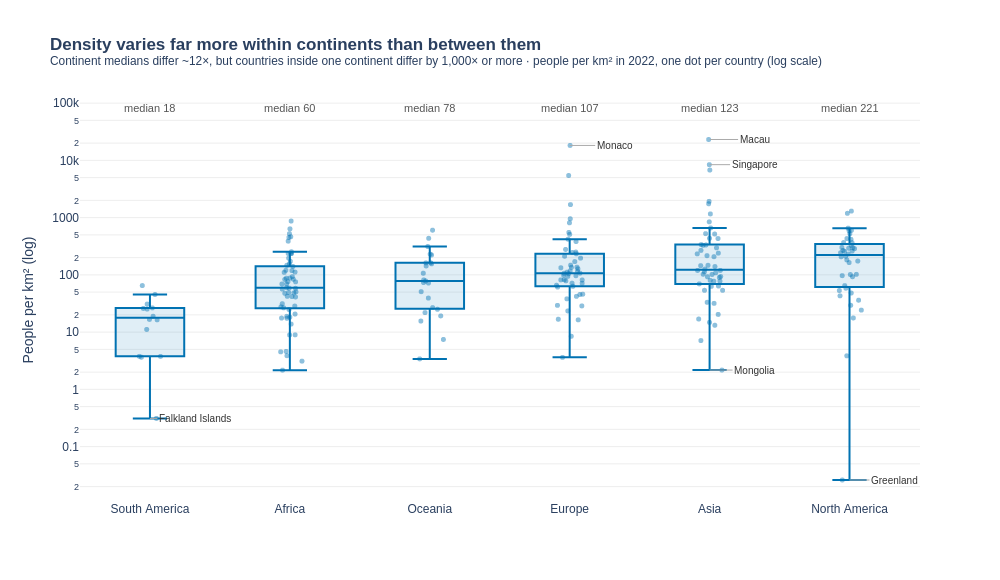

,Countries,min,25%,Median,75%,max,Max ÷ Min
Continent,,,,,,,
South America,14,0.31,5.6,17.8,26.4,65.0,209×
Africa,57,2.17,26.6,59.7,140.3,871.9,403×
Oceania,23,3.40,25.9,78.2,162.2,603.2,177×
Europe,50,3.62,63.8,106.9,228.0,"18,234.5","5,037×"
Asia,50,2.17,71.5,123.0,336.3,"23,172.3","10,665×"
North America,40,0.03,63.3,221.4,335.5,"1,299.3","49,780×"


In [9]:
# Q4 — Box plot: population density by continent (log scale)
BOX = '#0072B2'
order = df.groupby('Continent')['Density'].median().sort_values().index.tolist()

fig = px.box(df, x='Continent', y='Density', points='all', hover_name='Country',
             category_orders={'Continent': order}, log_y=True,
             template='plotly_white',
             title="<b>Density varies far more within continents than between them</b>"
                   "<br><sup>Continent medians differ ~12×, but countries inside one continent differ by "
                   "1,000× or more · people per km² in 2022, one dot per country (log scale)</sup>")

fig.update_traces(marker=dict(color=BOX, size=5, opacity=0.45),
                  line=dict(color=BOX), fillcolor='rgba(0,114,178,0.12)',
                  jitter=0.4, pointpos=0, boxmean=False)

# Median labels above each box
med = df.groupby('Continent')['Density'].median()
for c in order:
    fig.add_annotation(x=c, y=np.log10(df['Density'].max()) + 0.55, text=f"median {med[c]:.0f}",
                       showarrow=False, font=dict(size=11, color='#555555'))

# Label the extremes
for name in ['Macau', 'Monaco', 'Singapore', 'Greenland', 'Mongolia', 'Falkland Islands']:
    r = df[df['Country'] == name].iloc[0]
    fig.add_annotation(x=r['Continent'], y=np.log10(r['Density']), text=name,
                       showarrow=True, arrowhead=0, ax=45, ay=0,
                       font=dict(size=10, color='#333333'), arrowcolor='#AAAAAA')

fig.update_layout(height=580, margin=dict(t=100), showlegend=False)
fig.update_xaxes(title=None, showgrid=False)
fig.update_yaxes(title='People per km² (log)', showgrid=True, gridcolor='#EEEEEE')
fig.show()

# Summary table — density spread by continent
q4_table = (df.groupby('Continent')['Density']
              .describe()[['count', 'min', '25%', '50%', '75%', 'max']]
              .rename(columns={'count': 'Countries', '50%': 'Median'})
              .sort_values('Median'))
q4_table['Max ÷ Min'] = q4_table['max'] / q4_table['min']
fmt = {col: '{:,.1f}' for col in ['min', '25%', 'Median', '75%', 'max']}
fmt.update({'min': '{:,.2f}', 'Countries': '{:.0f}', 'Max ÷ Min': '{:,.0f}×'})
display(q4_table.style.format(fmt))

---
## Q5 — Where did populations grow — and where did they shrink?

Which countries' populations **grew and which shrank between 2000 and 2022** (percentage change), and where in the world are they?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.*

The question asks *where* populations grew or shrank, so a map was the obvious choice. With a table or a bar chart you'd have to already know where Lithuania or Moldova are; on a map the pattern just jumps out.

Since the data has a natural middle point (0% change), I used a diverging colour scale: orange for shrinking, purple for growing and white for roughly no change. I avoided red and green so colour-blind readers can still read it. One problem I ran into was Qatar, which grew by over 300%. If I let the scale go that high, all the shrinking countries looked almost white and you couldn't see them, so I capped the colours at ±40%. The exact numbers are still there when you hover. Once I did that, the cluster of shrinking countries in Eastern Europe and the Balkans became really clear.

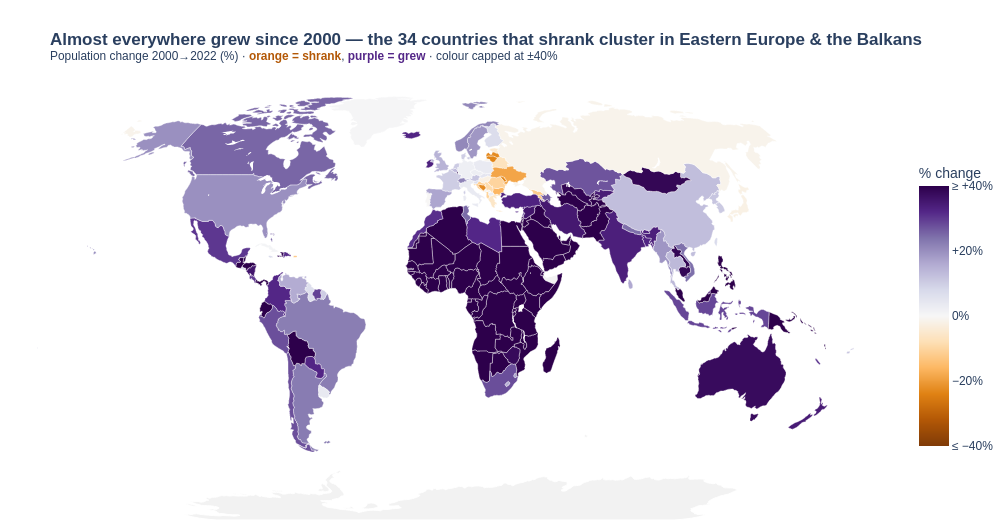

Grew: 200 · Shrank: 34


,Group,Country,Continent,2000 Population,2022 Population,Change
0,Shrank most,Northern Mariana Islands,Oceania,"80,338","49,551",-38.3%
1,Shrank most,American Samoa,Oceania,"58,230","44,273",-24.0%
2,Shrank most,Lithuania,Europe,"3,599,637","2,750,055",-23.6%
3,Shrank most,Marshall Islands,Oceania,"54,224","41,569",-23.3%
4,Shrank most,Moldova,Europe,"4,251,573","3,272,996",-23.0%
5,Shrank most,Latvia,Europe,"2,392,530","1,850,651",-22.6%
6,Shrank most,Bosnia and Herzegovina,Europe,"4,179,350","3,233,526",-22.6%
7,Shrank most,Vatican City,Europe,651,510,-21.7%
8,Shrank most,Wallis and Futuna,Oceania,"14,723","11,572",-21.4%
9,Shrank most,Ukraine,Europe,"48,879,755","39,701,739",-18.8%


In [10]:
# Q5 — Choropleth: % population change 2000 → 2022
chg = df.assign(Change=(df['2022 Population'] / df['2000 Population'] - 1) * 100)
n_shrank = (chg['Change'] < 0).sum()

fig = px.choropleth(chg, locations='CCA3', locationmode='ISO-3', color='Change',
                    hover_name='Country',
                    hover_data={'CCA3': False, 'Change': ':.1f'},
                    color_continuous_scale='PuOr',          # orange = shrink, purple = grow
                    color_continuous_midpoint=0, range_color=[-40, 40],
                    template='plotly_white',
                    title=f"<b>Almost everywhere grew since 2000 — the {n_shrank} countries that shrank "
                          f"cluster in Eastern Europe & the Balkans</b>"
                          f"<br><sup>Population change 2000→2022 (%) · "
                          f"<span style='color:#B35806'><b>orange = shrank</b></span>, "
                          f"<span style='color:#542788'><b>purple = grew</b></span> · "
                          f"colour capped at ±40%</sup>")

fig.update_geos(showframe=False, showcoastlines=False, projection_type='natural earth',
                showland=True, landcolor='#F2F2F2', showcountries=True, countrycolor='white')
fig.update_traces(marker_line_color='white', marker_line_width=0.4)
fig.update_layout(height=520, margin=dict(l=0, r=0, t=90, b=0),
                  coloraxis_colorbar=dict(title='% change', ticksuffix='%', len=0.7,
                                          tickvals=[-40, -20, 0, 20, 40],
                                          ticktext=['≤ −40%', '−20%', '0%', '+20%', '≥ +40%']))
fig.show()

# Summary table — biggest decliners and biggest growers 2000→2022
q5_table = pd.concat([chg.nsmallest(10, 'Change').assign(Group='Shrank most'),
                      chg.nlargest(10, 'Change').assign(Group='Grew most')])
q5_table = q5_table[['Group', 'Country', 'Continent', '2000 Population', '2022 Population', 'Change']].reset_index(drop=True)
print(f"Grew: {(chg['Change'] > 0).sum()} · Shrank: {n_shrank}")
display(q5_table.style.format({'2000 Population': '{:,.0f}', '2022 Population': '{:,.0f}', 'Change': '{:+.1f}%'}))

---
## Q6 — Where do the world's 8 billion people live?

How is the **2022 world population** distributed across **continents and the countries within them**? Show both levels in one figure.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.*

I needed to show two levels at the same time (continents, and the countries inside them), and a treemap does that nicely. Each country is a rectangle sized by its population, sitting inside its continent's rectangle, so you get both the big picture and the details in one figure. A pie chart wouldn't work with over 200 countries, and a stacked bar would get messy very quickly.

I made Asia blue and the other continents grey, because the main point is that almost 60% of all people live in Asia. Every tile shows the country's name and its share of the world, so there's no need for a legend. Just by looking at it you can see that China and India alone are bigger than whole continents.

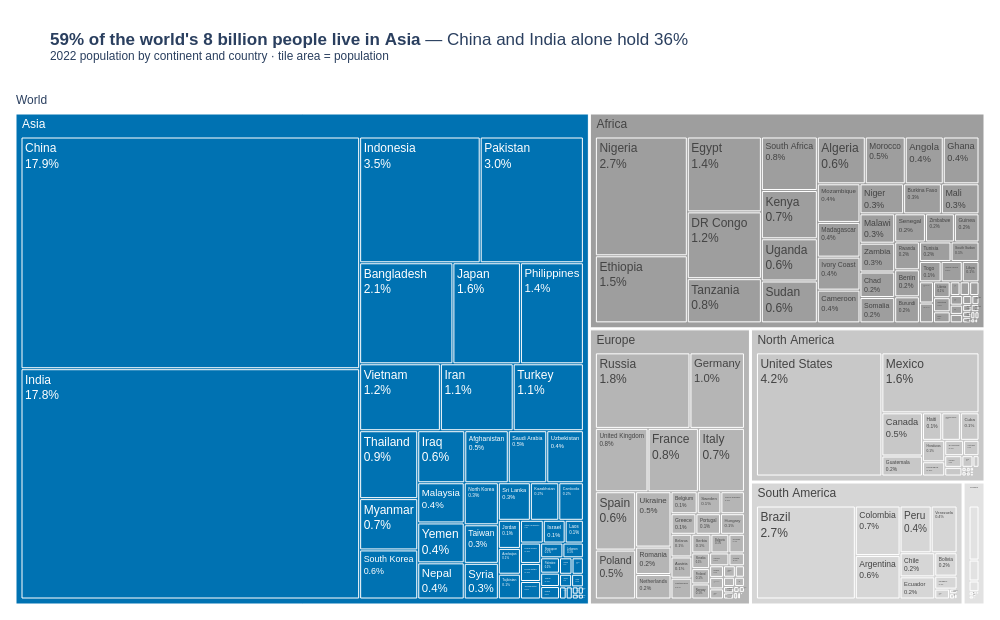

,Population,Countries,World share (%),Largest country
Continent,,,,
Asia,"4,721,383,274",50,59.2%,China
Africa,"1,426,730,932",57,17.9%,Nigeria
Europe,"743,147,538",50,9.3%,Russia
North America,"600,296,136",40,7.5%,United States
South America,"436,816,608",14,5.5%,Brazil
Oceania,"45,038,554",23,0.6%,Australia


In [11]:
# Q6 — Treemap: world population 2022, continent → country
COL = {'Asia': '#0072B2', 'Africa': '#9E9E9E', 'Europe': '#B5B5B5',
       'North America': '#C8C8C8', 'South America': '#D6D6D6', 'Oceania': '#E2E2E2'}
asia_share = df.loc[df['Continent'] == 'Asia', '2022 Population'].sum() / df['2022 Population'].sum() * 100
ci_share = df.loc[df['Country'].isin(['China', 'India']), '2022 Population'].sum() / df['2022 Population'].sum() * 100

fig = px.treemap(df, path=[px.Constant('World'), 'Continent', 'Country'],
                 values='2022 Population', color='Continent',
                 color_discrete_map={**COL, '(?)': '#FFFFFF'},
                 template='plotly_white',
                 title=f"<b>{asia_share:.0f}% of the world's 8 billion people live in Asia</b> — "
                       f"China and India alone hold {ci_share:.0f}%"
                       f"<br><sup>2022 population by continent and country · "
                       f"tile area = population</sup>")

fig.update_traces(texttemplate='%{label}<br>%{percentRoot:.1%}',
                  hovertemplate='<b>%{label}</b><br>%{value:,.0f} people'
                                '<br>%{percentRoot:.1%} of world<extra></extra>',
                  marker=dict(line=dict(color='white', width=1)),
                  root_color='#FFFFFF', tiling=dict(pad=2))
fig.update_layout(height=620, margin=dict(l=10, r=10, t=90, b=10))
fig.show()

# Summary table — 2022 population and world share by continent (with largest country)
world = df['2022 Population'].sum()
q6_table = df.groupby('Continent').agg(Population=('2022 Population', 'sum'),
                                       Countries=('Country', 'count')).sort_values('Population', ascending=False)
q6_table['World share (%)'] = (q6_table['Population'] / world * 100).round(1)
q6_table['Largest country'] = df.loc[df.groupby('Continent')['2022 Population'].idxmax()].set_index('Continent')['Country']
display(q6_table.style.format({'Population': '{:,.0f}', 'World share (%)': '{:.1f}%'}))

---
## Q7 — Whose share of the world is rising?

How have the shares of world population held by **Africa, Asia and Europe** changed from 1970 to 2022? Group the other three continents as `'Rest of the world'`.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.*

This question is about *shares*, not about how many people there are, so I used a 100% stacked bar chart. Every bar is the same height (100% of the world), so the only thing that changes from year to year is how big each piece is. That's exactly what the question asks.

I coloured the two groups that changed the most: Africa in orange at the bottom and Europe in blue just above it. Putting them next to each other at the bottom makes it easy to watch Africa's piece grow while Europe's shrinks. Asia and the rest of the world are grey because they stayed more or less the same. I wrote the percentages inside the bars and the group names next to the last bar, so I could drop the y-axis and the legend. I also made sure the years are evenly spaced, because the data jumps from 2010 to 2015, 2020 and 2022 and the bars looked odd otherwise.

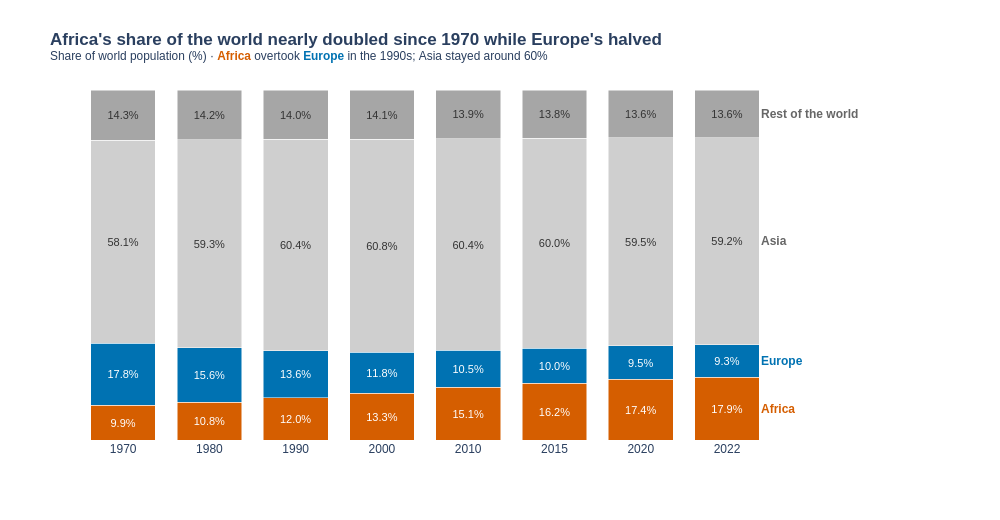

,Africa,Europe,Asia,Rest of the world
Year,,,,
1970,9.9%,17.8%,58.1%,14.3%
1980,10.8%,15.6%,59.3%,14.2%
1990,12.0%,13.6%,60.4%,14.0%
2000,13.3%,11.8%,60.8%,14.1%
2010,15.1%,10.5%,60.4%,13.9%
2015,16.2%,10.0%,60.0%,13.8%
2020,17.4%,9.5%,59.5%,13.6%
2022,17.9%,9.3%,59.2%,13.6%


In [12]:
# Q7 — 100% stacked bar: share of world population by group
grp = df_long.assign(Group=df_long['Continent'].where(
          df_long['Continent'].isin(['Africa', 'Asia', 'Europe']), 'Rest of the world'))
share = grp.groupby(['Year', 'Group'], as_index=False)['Population'].sum()
share['Share'] = share['Population'] / share.groupby('Year')['Population'].transform('sum') * 100
share['Year'] = share['Year'].astype(str)       # categorical x → evenly spaced bars

order = ['Africa', 'Europe', 'Asia', 'Rest of the world']   # changing groups at the base/top for easy reading
COL = {'Africa': '#D55E00', 'Europe': '#0072B2', 'Asia': '#CFCFCF', 'Rest of the world': '#A6A6A6'}

fig = px.bar(share, x='Year', y='Share', color='Group', text=share['Share'].round(1).astype(str) + '%',
             category_orders={'Group': order}, color_discrete_map=COL,
             template='plotly_white',
             title="<b>Africa's share of the world nearly doubled since 1970 while Europe's halved</b>"
                   "<br><sup>Share of world population (%) · "
                   "<span style='color:#D55E00'><b>Africa</b></span> overtook "
                   "<span style='color:#0072B2'><b>Europe</b></span> in the 1990s; "
                   "Asia stayed around 60%</sup>")

fig.update_traces(textposition='inside', insidetextanchor='middle', textfont_size=11)
fig.update_traces(selector=lambda t: t.name in ('Africa', 'Europe'), textfont_color='white')
fig.update_traces(selector=lambda t: t.name not in ('Africa', 'Europe'), textfont_color='#333333')

# Direct labels for each group to the right of the last bar (replaces the legend)
last = share[share['Year'] == '2022'].set_index('Group')
cum = 0
for g in order:
    v = last.loc[g, 'Share']
    fig.add_annotation(x=share['Year'].nunique() - 1, y=cum + v / 2,   # category index of the last bar
                       text=f"<b>{g}</b>", showarrow=False,
                       xanchor='left', xshift=32, font=dict(color=COL[g] if g in ('Africa', 'Europe') else '#666666'))
    cum += v

fig.update_layout(barmode='stack', bargap=0.25, showlegend=False, height=520,
                  margin=dict(t=90, r=140))
fig.update_xaxes(title=None, showgrid=False, type='category')
fig.update_yaxes(visible=False, range=[0, 100])
fig.show()

# Summary table — share of world population (%) by year
q7_table = share.pivot(index='Year', columns='Group', values='Share')[order]
q7_table.columns.name = None
display(q7_table.style.format('{:.1f}%'))